# Explore wavelet filters

In [1]:
import pywt, matplotlib.pyplot as plt

## List wavelets

In [2]:
pywt.wavelist()

['bior1.1',
 'bior1.3',
 'bior1.5',
 'bior2.2',
 'bior2.4',
 'bior2.6',
 'bior2.8',
 'bior3.1',
 'bior3.3',
 'bior3.5',
 'bior3.7',
 'bior3.9',
 'bior4.4',
 'bior5.5',
 'bior6.8',
 'cgau1',
 'cgau2',
 'cgau3',
 'cgau4',
 'cgau5',
 'cgau6',
 'cgau7',
 'cgau8',
 'cmor',
 'coif1',
 'coif2',
 'coif3',
 'coif4',
 'coif5',
 'coif6',
 'coif7',
 'coif8',
 'coif9',
 'coif10',
 'coif11',
 'coif12',
 'coif13',
 'coif14',
 'coif15',
 'coif16',
 'coif17',
 'db1',
 'db2',
 'db3',
 'db4',
 'db5',
 'db6',
 'db7',
 'db8',
 'db9',
 'db10',
 'db11',
 'db12',
 'db13',
 'db14',
 'db15',
 'db16',
 'db17',
 'db18',
 'db19',
 'db20',
 'db21',
 'db22',
 'db23',
 'db24',
 'db25',
 'db26',
 'db27',
 'db28',
 'db29',
 'db30',
 'db31',
 'db32',
 'db33',
 'db34',
 'db35',
 'db36',
 'db37',
 'db38',
 'dmey',
 'fbsp',
 'gaus1',
 'gaus2',
 'gaus3',
 'gaus4',
 'gaus5',
 'gaus6',
 'gaus7',
 'gaus8',
 'haar',
 'mexh',
 'morl',
 'rbio1.1',
 'rbio1.3',
 'rbio1.5',
 'rbio2.2',
 'rbio2.4',
 'rbio2.6',
 'rbio2.8',
 'rbio3.1',

## Show orthogonal wavelets
Synthesis matrix is the transpose of the analysis matrix. Therefore, we only show $\phi$ and $\psi$.

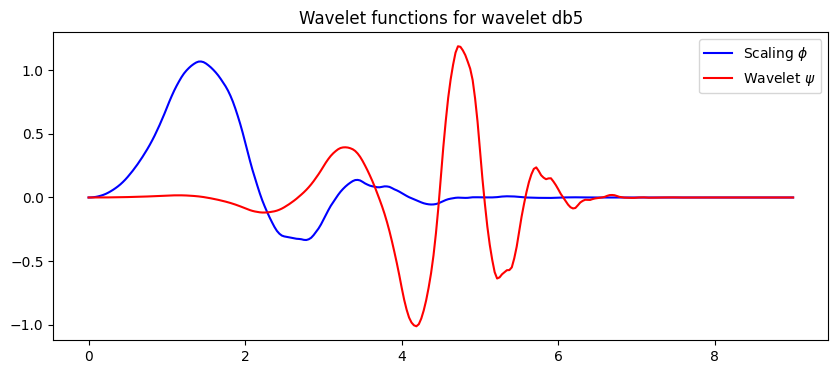

In [6]:
wavelet_name = "db5"

w = pywt.Wavelet(wavelet_name)
phi, psi, x = w.wavefun(level=5)

plt.figure(figsize=(10,4))
plt.plot(x, phi, 'b', label=r'Scaling $\phi$')
plt.plot(x, psi, 'r', label=r'Wavelet $\psi$')
plt.title(f'Wavelet functions for wavelet {wavelet_name}')
plt.legend()
plt.show()


## Show biorthogonal wavelets
Synthesis matrix is different from the analysis matrix.

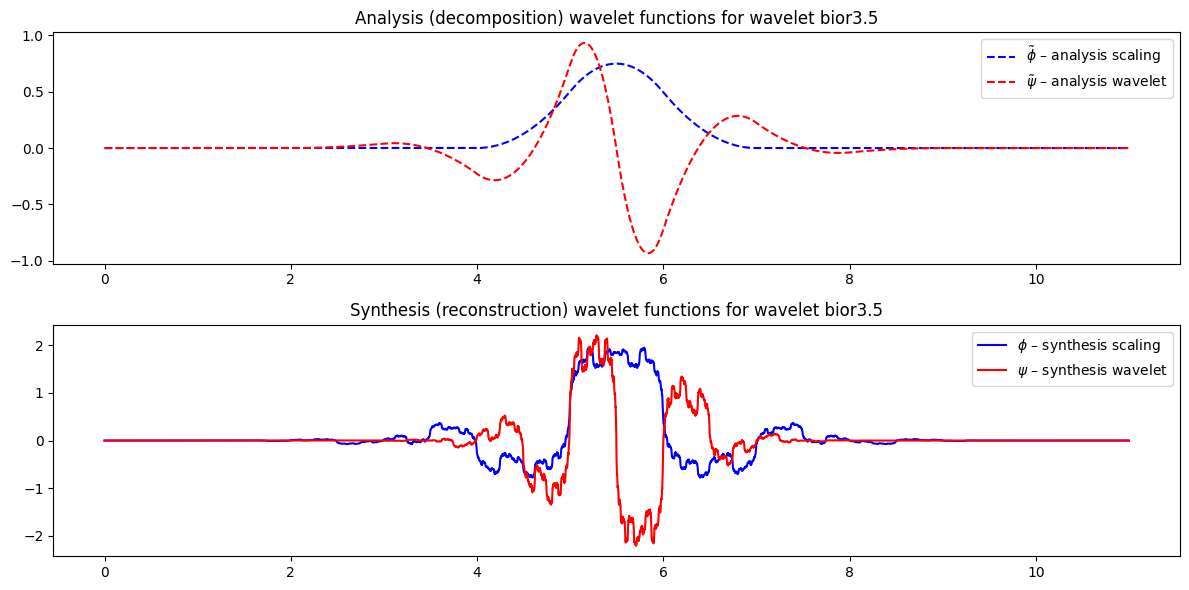

In [7]:
wavelet_name = "bior3.5"

# Choose a biorthogonal wavelet
w = pywt.Wavelet(wavelet_name)

# wavefun returns 5 values for biorthogonal wavelets
phi_rec, psi_rec, phi_dec, psi_dec, x = w.wavefun(level=10)

# Plot reconstruction functions
plt.figure(figsize=(12,6))


# Plot decomposition functions
plt.subplot(2,1,1)
plt.plot(x, phi_dec, 'b--', label=r'$\tilde\phi$ – analysis scaling')
plt.plot(x, psi_dec, 'r--', label=r'$\tilde\psi$ – analysis wavelet')
plt.title(f'Analysis (decomposition) wavelet functions for wavelet {wavelet_name}')
plt.legend()

plt.subplot(2,1,2)
plt.plot(x, phi_rec, 'b', label=r'$\phi$ – synthesis scaling')
plt.plot(x, psi_rec, 'r', label=r'$\psi$ – synthesis wavelet')
plt.title(f'Synthesis (reconstruction) wavelet functions for wavelet {wavelet_name}')
plt.legend()


plt.tight_layout()
plt.show()

## Show coefficients

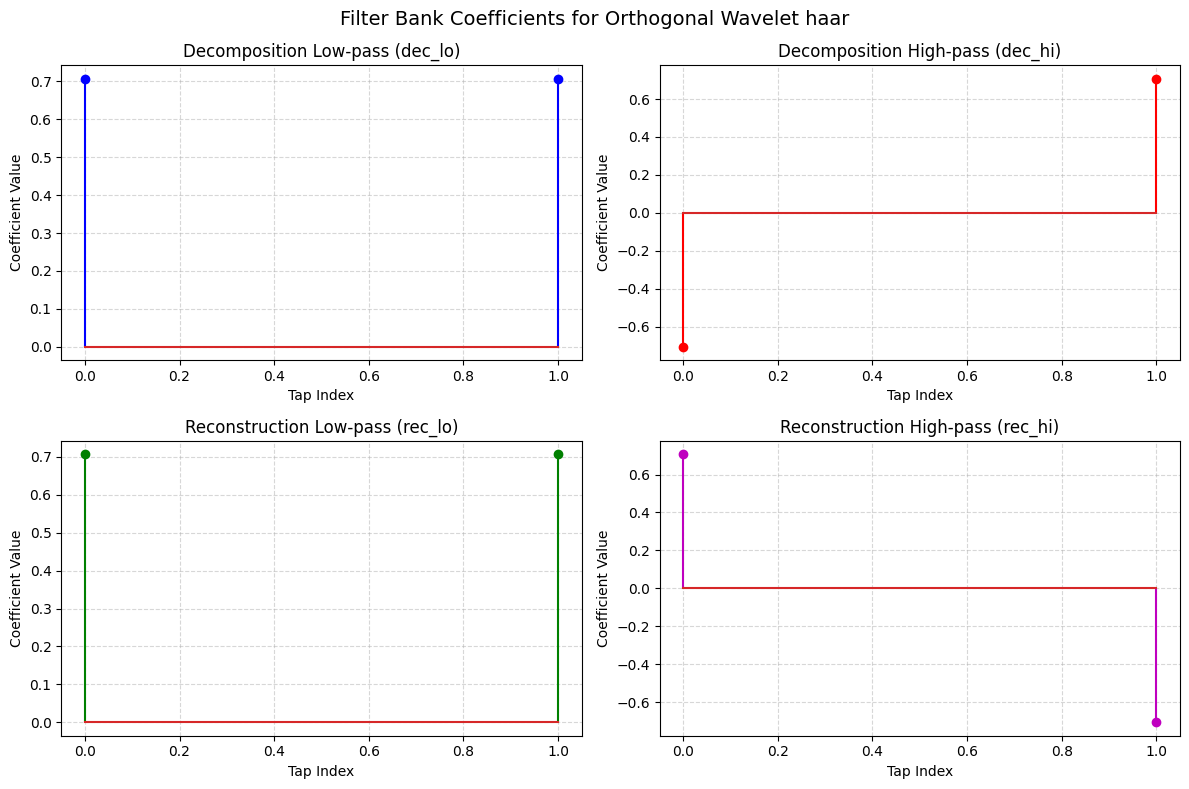

In [10]:
import matplotlib.pyplot as plt
import pywt

wavelet_name = "haar"
w = pywt.Wavelet(wavelet_name)

# Extract discrete filter coefficients
filters = {
    "Decomposition Low-pass (dec_lo)": w.dec_lo,
    "Decomposition High-pass (dec_hi)": w.dec_hi,
    "Reconstruction Low-pass (rec_lo)": w.rec_lo,
    "Reconstruction High-pass (rec_hi)": w.rec_hi,
}

# Plot discrete filter coefficients using stem plots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
colors = ["b", "r", "g", "m"]

for ax, (title, coeffs), color in zip(axes.flat, filters.items(), colors):
    ax.stem(coeffs, linefmt=f"{color}-", markerfmt=f"{color}o")
    ax.set_title(title)
    ax.set_xlabel("Tap Index")
    ax.set_ylabel("Coefficient Value")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.suptitle(f"Filter Bank Coefficients for Orthogonal Wavelet {wavelet_name}", fontsize=14)
plt.tight_layout()
plt.show()

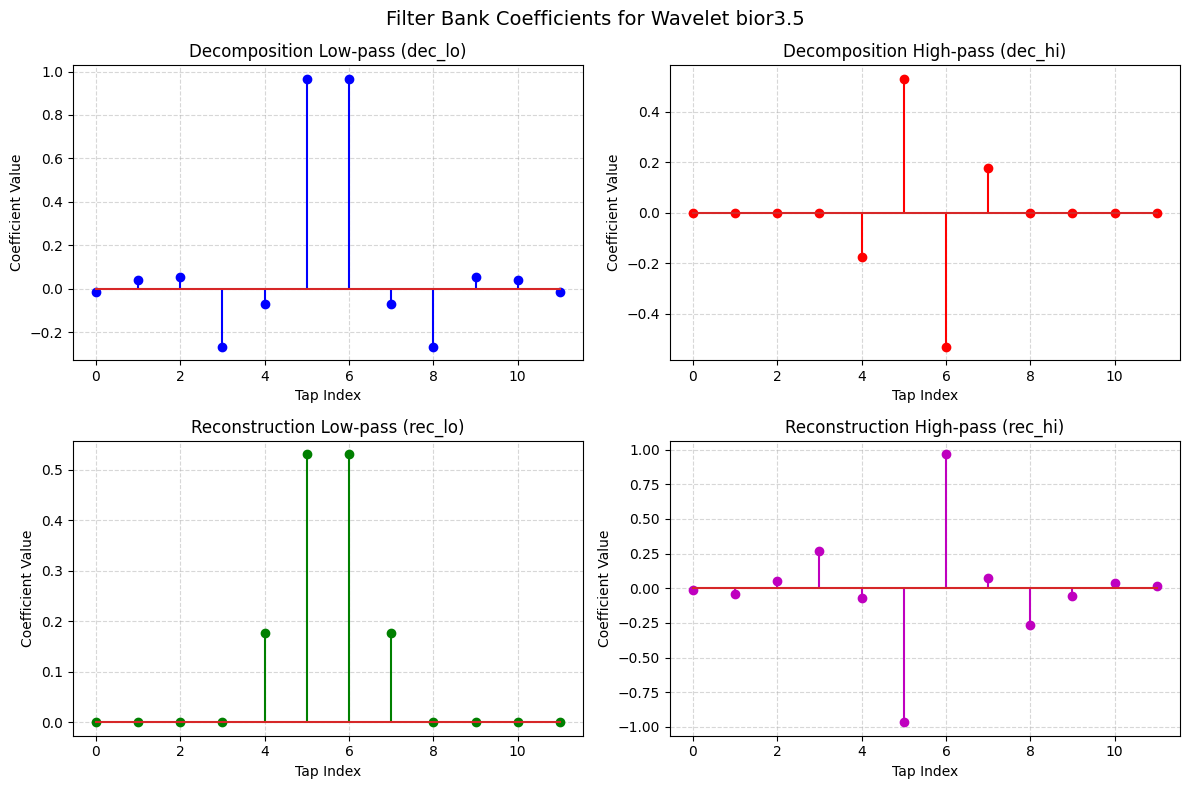

In [9]:
import matplotlib.pyplot as plt
import pywt

wavelet_name = "bior3.5"
w = pywt.Wavelet(wavelet_name)

# Extract discrete filter coefficients
filters = {
    "Decomposition Low-pass (dec_lo)": w.dec_lo,
    "Decomposition High-pass (dec_hi)": w.dec_hi,
    "Reconstruction Low-pass (rec_lo)": w.rec_lo,
    "Reconstruction High-pass (rec_hi)": w.rec_hi,
}

# Plot discrete filter coefficients using stem plots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
colors = ["b", "r", "g", "m"]

for ax, (title, coeffs), color in zip(axes.flat, filters.items(), colors):
    markerline, stemlines, baseline = ax.stem(coeffs, linefmt=f"{color}-", markerfmt=f"{color}o")
    ax.set_title(title)
    ax.set_xlabel("Tap Index")
    ax.set_ylabel("Coefficient Value")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.suptitle(f"Filter Bank Coefficients for Wavelet {wavelet_name}", fontsize=14)
plt.tight_layout()
plt.show()